<a href="https://colab.research.google.com/github/Monikha-K/Campus-Facility-Insights-DS/blob/main/Campus_Facility_Insight.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

import os

drive_path = "/content/drive/MyDrive/Campus_Facility_Insight_Dataset"

print("Files and folders in My Drive:")
for item in os.listdir(drive_path):
    print(item)


Files and folders in My Drive:
README.txt
dataset_validation_summary.csv
maintenance.csv
calendar.csv
bookings.csv
facilities.csv
occupancy.csv


In [ ]:

data_path = "/content/drive/MyDrive/Campus_Facility_Insight_Dataset"

print(os.listdir(data_path))


['README.txt', 'dataset_validation_summary.csv', 'maintenance.csv', 'calendar.csv', 'bookings.csv', 'facilities.csv', 'occupancy.csv']


In [ ]:

import pandas as pd
import os

bookings = pd.read_csv(os.path.join(data_path, "bookings.csv"))
facilities = pd.read_csv(os.path.join(data_path, "facilities.csv"))
occupancy = pd.read_csv(os.path.join(data_path, "occupancy.csv"))
calendar = pd.read_csv(os.path.join(data_path, "calendar.csv"))
maintenance = pd.read_csv(os.path.join(data_path, "maintenance.csv"))

print("All five datasets loaded successfully!")
print("Bookings:", bookings.shape)
print("Facilities:", facilities.shape)
print("Occupancy:", occupancy.shape)
print("Calendar:", calendar.shape)
print("Maintenance:", maintenance.shape)


All five datasets loaded successfully!
Bookings: (500, 8)
Facilities: (500, 9)
Occupancy: (500, 6)
Calendar: (500, 7)
Maintenance: (500, 8)


In [ ]:

import os
import numpy as np
import pandas as pd

data_path = "/content/drive/MyDrive/Campus_Facility_Insight_Dataset"

rng = np.random.default_rng(20261013)

# Cover the operational period and retain 500 unique dates.
dates = pd.date_range("2026-01-05", periods=500, freq="D")

exam_dates = {
    pd.Timestamp(d)
    for d in [
        "2026-04-10", "2026-04-11", "2026-04-12",
        "2026-06-15", "2026-06-16", "2026-06-17"
    ]
}

events = [
    "No Event", "Orientation", "Cultural Fest", "Sports Meet",
    "Guest Lecture", "Workshop Week", "Placement Drive",
    "Holiday Event", "Project Expo", "Convocation"
]

rows = []

for i, d in enumerate(dates, start=1):
    is_working = d.dayofweek < 5

    event = rng.choice(
        events,
        p=[0.70, 0.04, 0.04, 0.03, 0.04,
           0.04, 0.03, 0.03, 0.03, 0.02]
    )

    is_exam = d in exam_dates

    if is_exam:
        event = "Exam Period"

    rows.append({
        "calendar_id": f"CAL{i:04d}",
        "date": d.strftime("%Y-%m-%d"),
        "working_day": "Yes" if is_working else "No",
        "event": event,
        "exam_period": "Yes" if is_exam else "No",
        "day_of_week": d.day_name(),
        "semester": "Semester 1" if d.month <= 6 else "Semester 2"
    })

new_calendar = pd.DataFrame(rows)

new_calendar.to_csv(
    os.path.join(data_path, "calendar.csv"),
    index=False
)

print("Calendar regenerated successfully.")
print("Rows:", len(new_calendar))
print("Unique dates:", new_calendar["date"].nunique())
print("Exam dates:", (new_calendar["exam_period"] == "Yes").sum())
print("Date range:", new_calendar["date"].min(),
      "to", new_calendar["date"].max())


Calendar regenerated successfully.
Rows: 500
Unique dates: 500
Exam dates: 6
Date range: 2026-01-05 to 2027-05-19



---


## ROUND 2 — EDA AND FEATURE ENGINEERING

**Campus Facility Insight | Assessment: 30 marks**

### Dataset loading status

- **Bookings:** 500 rows × 8 columns
- **Facilities:** 500 rows × 9 columns
- **Occupancy:** 500 rows × 6 columns
- **Calendar:** 500 rows × 7 columns
- **Maintenance:** 500 rows × 8 columns

...

### 8.5 Exam vs Non-Exam Comparison


is_exam_period,readings,average_occupancy,average_utilization_pct,period
0,483,40.27,45.87,Non-exam
1,17,32.29,51.99,Exam



---


## STEP 4 — DATA VISUALIZATION

Each chart is displayed separately and saved as a high-resolution PNG.

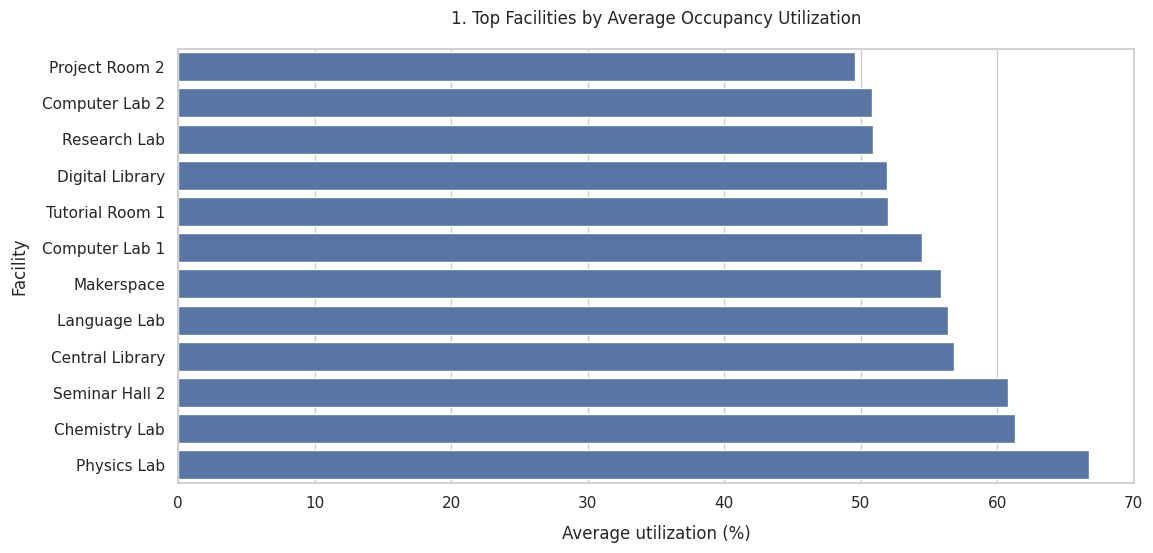

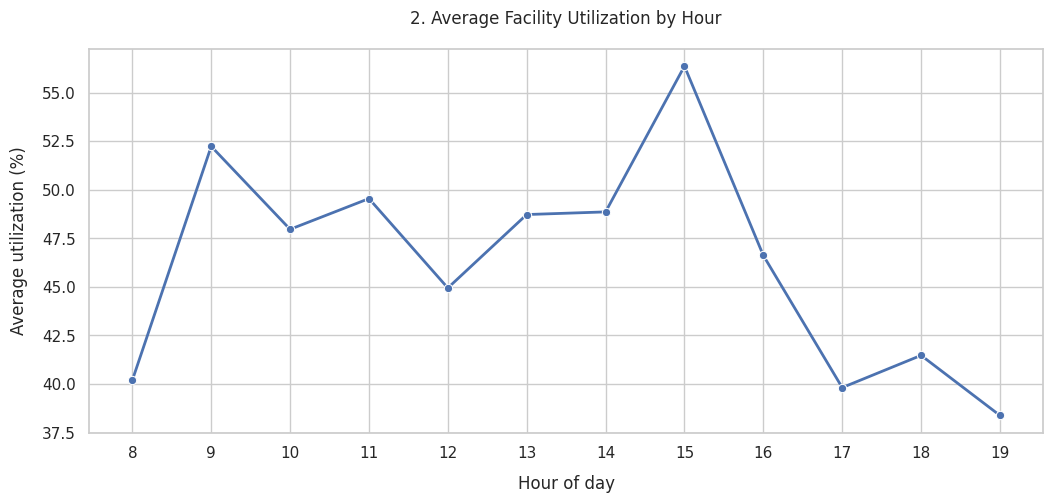

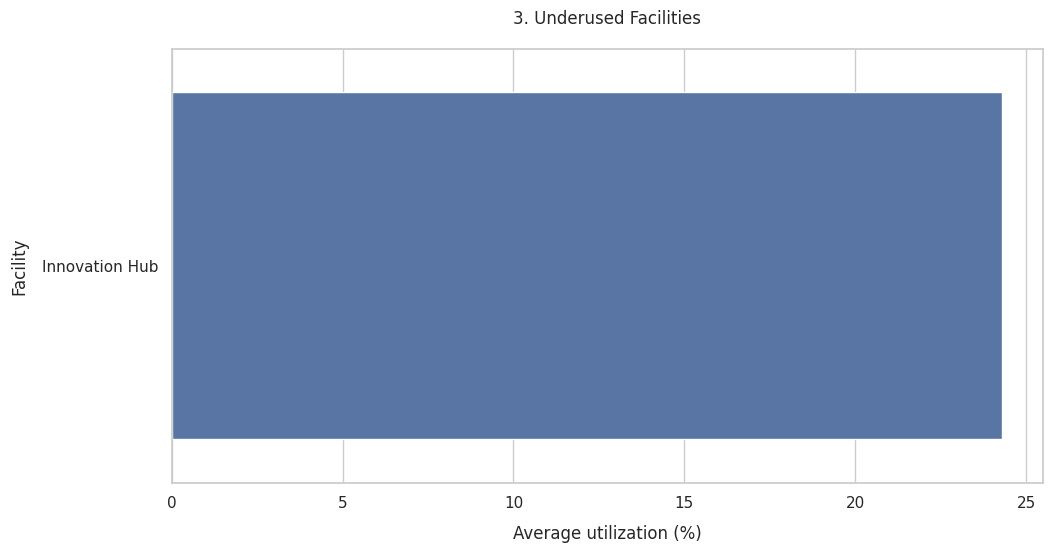

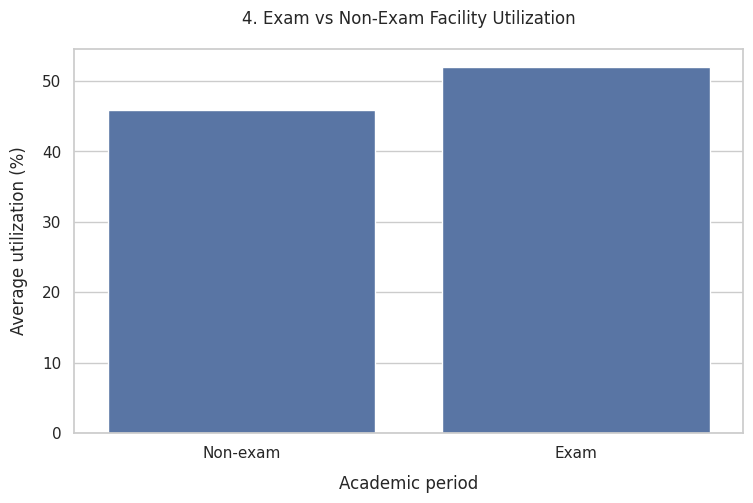

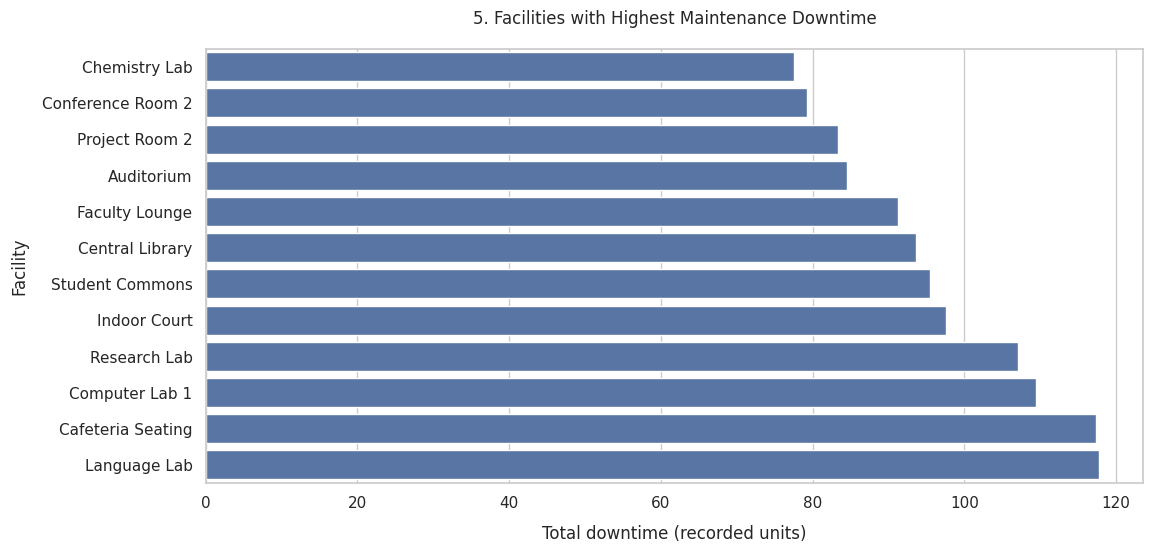

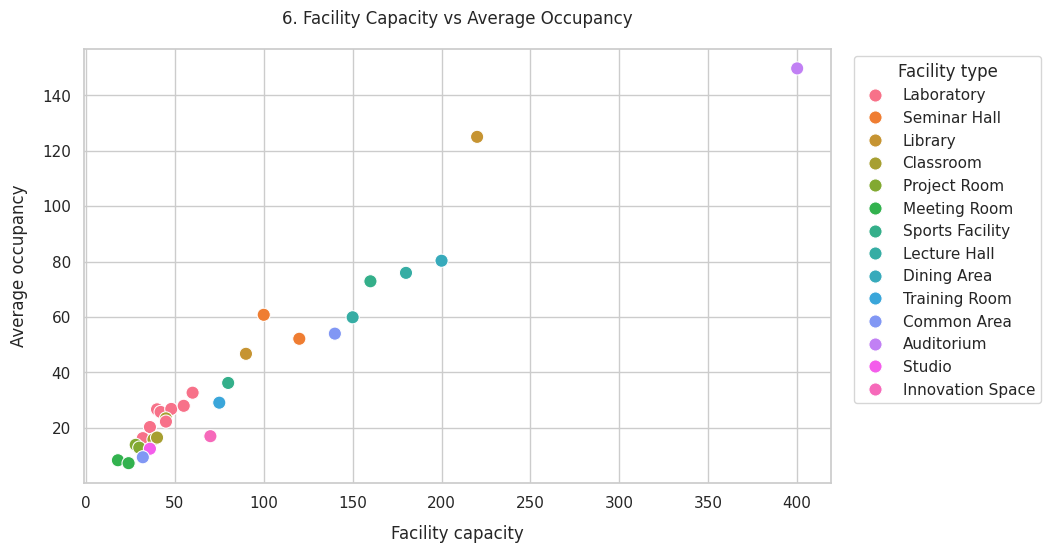

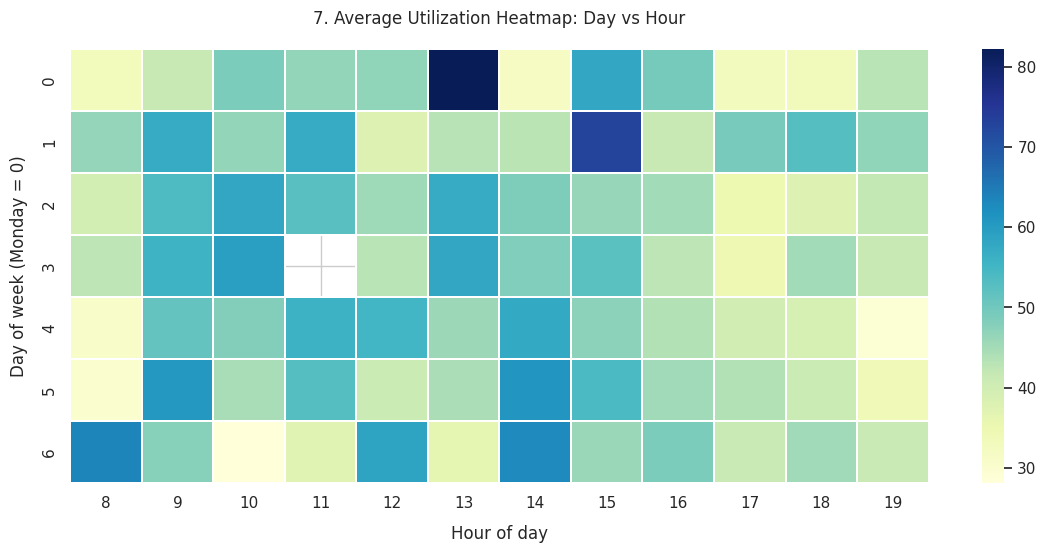


---


## STEP 5 — FEATURE ENGINEERING

Create derived variables and identify potentially useful features.

### Feature Selection Results


feature,relevance_score,selected
capacity,0.25,True
type_encoded,0.20,True
hour,0.05,True
day_of_week,0.04,True
is_working_day,0.02,True
is_weekend,0.01,False
is_exam_period,0.01,False


...

## ROUND 2 — COMPLETED

Review the exported files and check the graphs before submission.

### Deliverable Status


Deliverable,Status,Location
Cleaned datasets,Saved,Round2_Results
EDA summary tables,Saved,Round2_Results
Seven visualizations,Saved,Round2_Results/graphs
Feature selection,Saved,Round2_Results


Output directory:
/content/drive/MyDrive/Campus_Facility_Insight_Dataset/Round2_Results

Graph directory:
/content/drive/MyDrive/Campus_Facility_Insight_Dataset/Round2_Results/graphs

Saved files:
  - cleaned_bookings.csv
  - cleaned_calendar.csv
  - cleaned_facilities.csv
  - cleaned_maintenance.csv
  - cleaned_occupancy.csv
  - data_quality_report.csv
  - downtime_analysis.csv
  - duplicate_report.csv
  - exam_comparison.csv
  - facility_utilization.csv
  - feature_selection.csv
  - graphs
  - initial_dataset_overview.csv
  - peak_time_analysis.csv
  - underused_facilities.csv
  - utilization_categories.csv

Round 2 execution finished.
Synthetic data must be described as mock data in your report.


In [ ]:

# ================================================================
# CH30 - CAMPUS FACILITY INSIGHT
# ROUND 2: EDA AND FEATURE ENGINEERING
# Neatly formatted, complete Google Colab workflow
# ================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from sklearn.feature_selection import SelectKBest, mutual_info_regression
from sklearn.preprocessing import LabelEncoder

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

# ------------------------------------------------
# 1. GOOGLE DRIVE AND FILE PATHS
# ------------------------------------------------

from google.colab import drive

if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")

DATA_PATH = (
    "/content/drive/MyDrive/"
    "Campus_Facility_Insight_Dataset"
)

OUTPUT_PATH = os.path.join(DATA_PATH, "Round2_Results")
GRAPH_PATH = os.path.join(OUTPUT_PATH, "graphs")

os.makedirs(GRAPH_PATH, exist_ok=True)

# ------------------------------------------------
# DISPLAY HELPERS FOR NEAT NOTEBOOK OUTPUT
# ------------------------------------------------

def section(title, subtitle=None):
    display(Markdown("\n---\n"))
    display(Markdown(f"## {title}"))
    if subtitle:
        display(Markdown(subtitle))
    display(Markdown("\n"))

def subsection(title):
    display(Markdown(f"### {title}\n"))

def show_table(df, title=None, rows=20):
    if title:
        subsection(title)
    display(df.head(rows).style.format(precision=2).hide(axis="index"))
    display(Markdown("\n"))

def save_graph(filename):
    plt.tight_layout(pad=2.0)
    plt.savefig(
        os.path.join(GRAPH_PATH, filename),
        dpi=160,
        bbox_inches="tight",
        facecolor="white"
    )
    plt.show()
    plt.close()
    display(Markdown("\n"))

# ------------------------------------------------
# 2. LOAD ALL FIVE ORIGINAL DATASETS
# ------------------------------------------------

section(
    "ROUND 2 — EDA AND FEATURE ENGINEERING",
    "**Campus Facility Insight | Assessment: 30 marks**"
)

required_files = [
    "bookings.csv",
    "facilities.csv",
    "occupancy.csv",
    "calendar.csv",
    "maintenance.csv"
]

for filename in required_files:
    filepath = os.path.join(DATA_PATH, filename)
    if not os.path.exists(filepath):
        raise FileNotFoundError(
            f"Cannot find {filename}. Check the folder: {DATA_PATH}"
        )

bookings = pd.read_csv(os.path.join(DATA_PATH, "bookings.csv"))
facilities = pd.read_csv(os.path.join(DATA_PATH, "facilities.csv"))
occupancy = pd.read_csv(os.path.join(DATA_PATH, "occupancy.csv"))
calendar = pd.read_csv(os.path.join(DATA_PATH, "calendar.csv"))
maintenance = pd.read_csv(os.path.join(DATA_PATH, "maintenance.csv"))

datasets = {
    "Bookings": bookings,
    "Facilities": facilities,
    "Occupancy": occupancy,
    "Calendar": calendar,
    "Maintenance": maintenance
}

display(Markdown("### Dataset loading status"))
display(Markdown(
    "\n".join(
        f"- **{name}:** {df.shape[0]:,} rows × {df.shape[1]} columns"
        for name, df in datasets.items()
    )
))
display(Markdown("\n"))

# ------------------------------------------------
# 3. INITIAL DATA QUALITY INSPECTION
# ------------------------------------------------

section(
    "STEP 1 — DATA UNDERSTANDING",
    "Inspect row counts, column names, missing values, and duplicates."
)

overview_rows = []

for name, df in datasets.items():
    overview_rows.append({
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing Cells": int(df.isna().sum().sum()),
        "Duplicate Rows": int(df.duplicated().sum())
    })

overview = pd.DataFrame(overview_rows)
show_table(overview, "Dataset Overview")

for name, df in datasets.items():
    subsection(f"{name} — Sample Records")
    display(df.head(3))
    display(Markdown("\n"))

# ------------------------------------------------
# 4. STANDARDIZE FACILITY NAMES AND REMOVE DUPLICATES
# ------------------------------------------------

section(
    "STEP 2 — DATA PREPROCESSING",
    "Standardize facility names, remove duplicate records, and correct data types."
)

def normalize_facility(series):
    return (
        series.astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.casefold()
    )

for df in datasets.values():
    if "facility" in df.columns:
        df["facility"] = df["facility"].astype("string").str.strip()
        df["facility_key"] = normalize_facility(df["facility"])

duplicate_rows = []

for name, df in datasets.items():
    before = len(df)
    df.drop_duplicates(inplace=True)
    after_exact = len(df)

    if name == "Facilities":
        id_col = "facility_id"
    else:
        id_col = next(
            (c for c in df.columns
             if c.endswith("_id") and c != "facility_id"),
            None
        )

    if id_col:
        df.drop_duplicates(subset=[id_col], keep="first", inplace=True)

    duplicate_rows.append({
        "Dataset": name,
        "Exact Duplicates Removed": before - after_exact,
        "Rows After Deduplication": len(df)
    })

duplicate_report = pd.DataFrame(duplicate_rows)
show_table(duplicate_report, "Duplicate Record Report")

# Refresh references after cleaning.
bookings = datasets["Bookings"]
facilities = datasets["Facilities"]
occupancy = datasets["Occupancy"]
calendar = datasets["Calendar"]
maintenance = datasets["Maintenance"]

# Convert dates, times, and numeric fields.
bookings["date"] = pd.to_datetime(bookings["date"], errors="coerce")
bookings["start"] = pd.to_datetime(
    bookings["start"], format="%H:%M", errors="coerce"
)
bookings["end"] = pd.to_datetime(
    bookings["end"], format="%H:%M", errors="coerce"
)

occupancy["timestamp"] = pd.to_datetime(
    occupancy["timestamp"], errors="coerce"
)
occupancy["count"] = pd.to_numeric(occupancy["count"], errors="coerce")

calendar["date"] = pd.to_datetime(calendar["date"], errors="coerce")

maintenance["reported_date"] = pd.to_datetime(
    maintenance["reported_date"], errors="coerce"
)
maintenance["downtime"] = pd.to_numeric(
    maintenance["downtime"], errors="coerce"
)
facilities["capacity"] = pd.to_numeric(
    facilities["capacity"], errors="coerce"
)

# Prepare a unique facility lookup table.
facilities = facilities.dropna(
    subset=["facility", "capacity"]
).copy()

facilities = facilities[
    (facilities["facility"].str.len() > 0)
    & (facilities["capacity"] > 0)
].copy()

facilities = facilities.drop_duplicates(
    subset=["facility_key"], keep="first"
)

facility_lookup = facilities[
    ["facility_key", "facility", "type", "capacity", "block"]
].copy()

# Prepare the calendar table: one record per date.
calendar = calendar.dropna(subset=["date"]).copy()
calendar = calendar.drop_duplicates(subset=["date"], keep="first")

calendar_columns = [
    c for c in [
        "date", "working_day", "event", "exam_period", "semester"
    ]
    if c in calendar.columns
]

# ------------------------------------------------
# 5. CLEAN BOOKINGS AND CREATE FEATURES
# ------------------------------------------------

subsection("5.1 Booking preprocessing")

bookings = bookings.dropna(
    subset=["date", "start", "end", "facility_key"]
).copy()

bookings["booking_duration_hours"] = (
    (bookings["end"] - bookings["start"])
    .dt.total_seconds() / 3600
)

bookings.loc[
    bookings["booking_duration_hours"] <= 0,
    "booking_duration_hours"
] = np.nan

bookings["hour"] = bookings["start"].dt.hour
bookings["day_of_week"] = bookings["date"].dt.dayofweek
bookings["is_weekend"] = (
    bookings["day_of_week"] >= 5
).astype(int)

bookings = bookings.merge(
    facility_lookup.drop(columns=["facility"]),
    on="facility_key",
    how="left",
    validate="many_to_one"
)

bookings = bookings.merge(
    calendar[calendar_columns],
    on="date",
    how="left",
    validate="many_to_one",
    indicator="calendar_match"
)

bookings["calendar_matched"] = (
    bookings["calendar_match"] == "both"
).astype(int)

bookings.drop(columns=["calendar_match"], inplace=True)

print("Booking features created and calendar data merged.")
print("Bookings matched to calendar:", int(bookings["calendar_matched"].sum()))
print("Bookings without calendar match:", int((bookings["calendar_matched"] == 0).sum()))

# ------------------------------------------------
# 6. CLEAN OCCUPANCY AND HANDLE ANOMALIES
# ------------------------------------------------

subsection("6.1 Occupancy preprocessing")

occupancy = occupancy.dropna(
    subset=["timestamp", "facility_key"]
).copy()

occupancy["date"] = occupancy["timestamp"].dt.normalize()
occupancy["hour"] = occupancy["timestamp"].dt.hour
occupancy["day_of_week"] = occupancy["timestamp"].dt.dayofweek
occupancy["is_weekend"] = (
    occupancy["day_of_week"] >= 5
).astype(int)

occupancy = occupancy.merge(
    facility_lookup.drop(columns=["facility"]),
    on="facility_key",
    how="left",
    validate="many_to_one"
)

occupancy["count_missing"] = occupancy["count"].isna().astype(int)

occupancy["negative_count"] = (
    occupancy["count"].notna() & (occupancy["count"] < 0)
).astype(int)

occupancy["over_capacity"] = (
    occupancy["count"].notna()
    & occupancy["capacity"].notna()
    & (occupancy["count"] > occupancy["capacity"])
).astype(int)

quality_summary = pd.DataFrame({
    "Issue": [
        "Missing occupancy readings",
        "Negative occupancy readings",
        "Readings above facility capacity"
    ],
    "Records": [
        int(occupancy["count_missing"].sum()),
        int(occupancy["negative_count"].sum()),
        int(occupancy["over_capacity"].sum())
    ]
})

show_table(quality_summary, "Occupancy Quality Issues")

# Preserve the original count; create a separate analytical value.
occupancy["count_clean"] = occupancy["count"].where(
    (occupancy["over_capacity"] == 0)
    & (occupancy["negative_count"] == 0)
)

facility_medians = occupancy.groupby(
    "facility_key"
)["count_clean"].median()

overall_median = occupancy["count_clean"].median()

if pd.isna(overall_median):
    overall_median = 0

occupancy["count_clean"] = occupancy["count_clean"].fillna(
    occupancy["facility_key"].map(facility_medians)
).fillna(overall_median)

occupancy["count_clean"] = occupancy["count_clean"].clip(lower=0)

occupancy["count_clean"] = np.minimum(
    occupancy["count_clean"], occupancy["capacity"]
)

occupancy["occupancy_percentage"] = (
    occupancy["count_clean"] / occupancy["capacity"] * 100
)

# Join calendar information.
occupancy = occupancy.merge(
    calendar[calendar_columns],
    on="date",
    how="left",
    validate="many_to_one",
    indicator="calendar_match"
)

occupancy["calendar_matched"] = (
    occupancy["calendar_match"] == "both"
).astype(int)

occupancy.drop(columns=["calendar_match"], inplace=True)

# IMPORTANT: Unmatched calendar flags remain missing.
exam_text = (
    occupancy["exam_period"].astype("string")
    .str.strip().str.casefold()
)
working_text = (
    occupancy["working_day"].astype("string")
    .str.strip().str.casefold()
)

occupancy["is_exam_period"] = exam_text.map(
    {"yes": 1, "no": 0}
).astype("Int64")

occupancy["is_working_day"] = working_text.map(
    {"yes": 1, "no": 0}
).astype("Int64")

calendar_match_summary = pd.DataFrame({
    "Calendar Match Status": [
        "Matched",
        "Unmatched"
    ],
    "Occupancy Records": [
        int((occupancy["calendar_matched"] == 1).sum()),
        int((occupancy["calendar_matched"] == 0).sum())
    ]
})

show_table(calendar_match_summary, "Occupancy Calendar Matching")

# ------------------------------------------------
# 7. CLEAN MAINTENANCE RECORDS
# ------------------------------------------------

subsection("7.1 Maintenance preprocessing")

maintenance = maintenance.dropna(
    subset=["facility_key", "reported_date"]
).copy()

maintenance["downtime_missing"] = (
    maintenance["downtime"].isna()
).astype(int)

maintenance.loc[
    maintenance["downtime"] < 0, "downtime"
] = np.nan

maintenance["issue"] = (
    maintenance["issue"].fillna("").astype(str).str.strip()
)

maintenance.loc[
    maintenance["issue"] == "", "issue"
] = "Unknown"

downtime_median = maintenance["downtime"].median()

if pd.isna(downtime_median):
    downtime_median = 0

maintenance["downtime_clean"] = maintenance["downtime"].fillna(
    downtime_median
).clip(lower=0)

print("Maintenance records cleaned.")

# ------------------------------------------------
# 8. EXPLORATORY DATA ANALYSIS
# ------------------------------------------------

section(
    "STEP 3 — EXPLORATORY DATA ANALYSIS",
    "Answer the business questions using descriptive statistics and summary tables."
)

# 8.1 Facility utilization.
facility_usage = (
    occupancy.groupby(
        ["facility", "type", "capacity"], dropna=False
    )
    .agg(
        readings=("count_clean", "size"),
        average_occupancy=("count_clean", "mean"),
        maximum_occupancy=("count_clean", "max"),
        average_utilization_pct=("occupancy_percentage", "mean")
    )
    .reset_index()
    .sort_values("average_utilization_pct", ascending=False)
)

show_table(
    facility_usage.head(10),
    "8.1 Top Facilities by Average Utilization"
)

# 8.2 Peak-time analysis.
hourly_usage = (
    occupancy.groupby("hour")
    .agg(
        average_occupancy=("count_clean", "mean"),
        average_utilization_pct=("occupancy_percentage", "mean"),
        readings=("count_clean", "size")
    )
    .reset_index()
)

show_table(hourly_usage, "8.2 Hourly Utilization")

# 8.3 Underused facilities.
UNDERUSE_THRESHOLD = 25

underused = facility_usage[
    facility_usage["average_utilization_pct"] < UNDERUSE_THRESHOLD
].copy()

show_table(
    underused.sort_values("average_utilization_pct"),
    f"8.3 Underused Facilities (Below {UNDERUSE_THRESHOLD}%)"
)

# 8.4 Maintenance downtime.
downtime_summary = (
    maintenance.groupby("facility")
    .agg(
        work_orders=("work_order_id", "count"),
        total_downtime=("downtime_clean", "sum"),
        average_downtime=("downtime_clean", "mean")
    )
    .reset_index()
    .sort_values("total_downtime", ascending=False)
)

show_table(
    downtime_summary.head(10),
    "8.4 Facilities with Highest Maintenance Downtime"
)

# 8.5 Exam vs non-exam comparison.
matched_occupancy = occupancy[
    (occupancy["calendar_matched"] == 1)
    & occupancy["is_exam_period"].notna()
].copy()

if not matched_occupancy.empty:
    exam_comparison = (
        matched_occupancy.groupby("is_exam_period")
        .agg(
            readings=("count_clean", "size"),
            average_occupancy=("count_clean", "mean"),
            average_utilization_pct=("occupancy_percentage", "mean")
        )
        .reset_index()
    )

    exam_comparison["period"] = exam_comparison[
        "is_exam_period"
    ].map({0: "Non-exam", 1: "Exam"})
else:
    exam_comparison = pd.DataFrame(columns=[
        "is_exam_period", "readings",
        "average_occupancy", "average_utilization_pct", "period"
    ])

show_table(exam_comparison, "8.5 Exam vs Non-Exam Comparison")

# ------------------------------------------------
# 9. VISUALIZATIONS — SPACED AND ALIGNED
# ------------------------------------------------

section(
    "STEP 4 — DATA VISUALIZATION",
    "Each chart is displayed separately and saved as a high-resolution PNG."
)

# Graph 1: Facility utilization.
plot_data = facility_usage.head(12).sort_values(
    "average_utilization_pct", ascending=True
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=plot_data,
    x="average_utilization_pct",
    y="facility"
)
plt.title("1. Top Facilities by Average Occupancy Utilization", pad=18)
plt.xlabel("Average utilization (%)", labelpad=10)
plt.ylabel("Facility", labelpad=10)
save_graph("01_facility_utilization.png")

# Graph 2: Peak-time analysis.
plt.figure(figsize=(11, 5.5))
sns.lineplot(
    data=hourly_usage,
    x="hour",
    y="average_utilization_pct",
    marker="o",
    linewidth=2
)
plt.title("2. Average Facility Utilization by Hour", pad=18)
plt.xlabel("Hour of day", labelpad=10)
plt.ylabel("Average utilization (%)", labelpad=10)
plt.xticks(range(8, 20))
save_graph("02_peak_time_analysis.png")

# Graph 3: Underused facilities.
plot_data = underused.sort_values(
    "average_utilization_pct", ascending=True
).head(15)

plt.figure(figsize=(11, 6))
if not plot_data.empty:
    sns.barplot(
        data=plot_data,
        x="average_utilization_pct",
        y="facility"
    )
else:
    plt.text(
        0.5, 0.5, "No facilities below the selected threshold",
        ha="center", va="center"
    )
plt.title("3. Underused Facilities", pad=18)
plt.xlabel("Average utilization (%)", labelpad=10)
plt.ylabel("Facility", labelpad=10)
save_graph("03_underused_facilities.png")

# Graph 4: Exam comparison.
plt.figure(figsize=(8, 5.5))
if not exam_comparison.empty:
    sns.barplot(
        data=exam_comparison,
        x="period",
        y="average_utilization_pct"
    )
else:
    plt.text(
        0.5, 0.5, "No matched exam calendar records",
        ha="center", va="center"
    )
plt.title("4. Exam vs Non-Exam Facility Utilization", pad=18)
plt.xlabel("Academic period", labelpad=10)
plt.ylabel("Average utilization (%)", labelpad=10)
save_graph("04_exam_comparison.png")

# Graph 5: Maintenance downtime.
plot_data = downtime_summary.head(12).sort_values(
    "total_downtime", ascending=True
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=plot_data,
    x="total_downtime",
    y="facility"
)
plt.title("5. Facilities with Highest Maintenance Downtime", pad=18)
plt.xlabel("Total downtime (recorded units)", labelpad=10)
plt.ylabel("Facility", labelpad=10)
save_graph("05_maintenance_downtime.png")

# Graph 6: Capacity vs occupancy.
plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=facility_usage,
    x="capacity",
    y="average_occupancy",
    hue="type",
    s=90
)
plt.title("6. Facility Capacity vs Average Occupancy", pad=18)
plt.xlabel("Facility capacity", labelpad=10)
plt.ylabel("Average occupancy", labelpad=10)
plt.legend(
    title="Facility type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
save_graph("06_capacity_vs_occupancy.png")

# Graph 7: Utilization heatmap.
heatmap_data = occupancy.pivot_table(
    index="day_of_week",
    columns="hour",
    values="occupancy_percentage",
    aggfunc="mean"
)

plt.figure(figsize=(12, 6))
sns.heatmap(
    heatmap_data,
    cmap="YlGnBu",
    annot=False,
    linewidths=0.3
)
plt.title("7. Average Utilization Heatmap: Day vs Hour", pad=18)
plt.xlabel("Hour of day", labelpad=10)
plt.ylabel("Day of week (Monday = 0)", labelpad=10)
save_graph("07_utilization_heatmap.png")

# ------------------------------------------------
# 10. FEATURE ENGINEERING AND FEATURE SELECTION
# ------------------------------------------------

section(
    "STEP 5 — FEATURE ENGINEERING",
    "Create derived variables and identify potentially useful features."
)

occupancy["utilization_category"] = pd.cut(
    occupancy["occupancy_percentage"],
    bins=[-0.01, 25, 60, 85, 100],
    labels=["Low", "Moderate", "High", "Very High"]
)

occupancy["peak_period"] = occupancy["hour"].isin(
    [9, 10, 11, 14, 15, 16]
).astype(int)

feature_data = occupancy[
    [
        "occupancy_percentage",
        "hour",
        "day_of_week",
        "is_weekend",
        "capacity",
        "is_exam_period",
        "is_working_day",
        "type"
    ]
].dropna().copy()

feature_data["type_encoded"] = LabelEncoder().fit_transform(
    feature_data["type"].astype(str)
)

feature_columns = [
    "hour",
    "day_of_week",
    "is_weekend",
    "capacity",
    "is_exam_period",
    "is_working_day",
    "type_encoded"
]

X = feature_data[feature_columns].astype(float)
y = feature_data["occupancy_percentage"].astype(float)

if len(feature_data) >= 10 and y.nunique() > 1:
    selector = SelectKBest(
        score_func=mutual_info_regression,
        k=min(5, len(feature_columns))
    )
    selector.fit(X, y)

    feature_selection = pd.DataFrame({
        "feature": feature_columns,
        "relevance_score": selector.scores_,
        "selected": selector.get_support()
    }).sort_values("relevance_score", ascending=False)
else:
    feature_selection = pd.DataFrame({
        "feature": feature_columns,
        "relevance_score": np.nan,
        "selected": False
    })

show_table(feature_selection, "Feature Selection Results")

category_counts = (
    occupancy["utilization_category"]
    .value_counts(dropna=False)
    .rename_axis("category")
    .reset_index(name="records")
)

show_table(category_counts, "Utilization Category Distribution")

# ------------------------------------------------
# 11. SAVE CLEANED DATASETS AND ANALYSIS TABLES
# ------------------------------------------------

section(
    "STEP 6 — EXPORT RESULTS",
    "All files are saved in the Round2_Results folder in Google Drive."
)

cleaned_datasets = {
    "cleaned_bookings.csv": bookings,
    "cleaned_facilities.csv": facilities,
    "cleaned_occupancy.csv": occupancy,
    "cleaned_calendar.csv": calendar,
    "cleaned_maintenance.csv": maintenance
}

for filename, df in cleaned_datasets.items():
    df.to_csv(os.path.join(OUTPUT_PATH, filename), index=False)

analysis_tables = {
    "facility_utilization.csv": facility_usage,
    "peak_time_analysis.csv": hourly_usage,
    "underused_facilities.csv": underused,
    "exam_comparison.csv": exam_comparison,
    "downtime_analysis.csv": downtime_summary,
    "feature_selection.csv": feature_selection,
    "utilization_categories.csv": category_counts,
    "data_quality_report.csv": pd.DataFrame([
        {
            "dataset": name,
            "rows_after_cleaning": len(df),
            "columns": len(df.columns),
            "missing_cells": int(df.isna().sum().sum()),
            "duplicate_rows_remaining": int(df.duplicated().sum())
        }
        for name, df in cleaned_datasets.items()
    ]),
    "initial_dataset_overview.csv": overview,
    "duplicate_report.csv": duplicate_report
}

for filename, df in analysis_tables.items():
    df.to_csv(os.path.join(OUTPUT_PATH, filename), index=False)

# ------------------------------------------------
# 12. FINAL STATUS REPORT
# ------------------------------------------------

section(
    "ROUND 2 — COMPLETED",
    "Review the exported files and check the graphs before submission."
)

final_status = pd.DataFrame([
    {
        "Deliverable": "Cleaned datasets",
        "Status": "Saved",
        "Location": "Round2_Results"
    },
    {
        "Deliverable": "EDA summary tables",
        "Status": "Saved",
        "Location": "Round2_Results"
    },
    {
        "Deliverable": "Seven visualizations",
        "Status": "Saved",
        "Location": "Round2_Results/graphs"
    },
    {
        "Deliverable": "Feature selection",
        "Status": "Saved",
        "Location": "Round2_Results"
    }
])

show_table(final_status, "Deliverable Status")

print("Output directory:")
print(OUTPUT_PATH)

print("\nGraph directory:")
print(GRAPH_PATH)

print("\nSaved files:")
for filename in sorted(os.listdir(OUTPUT_PATH)):
    print("  -", filename)

print("\nRound 2 execution finished.")
print("Synthetic data must be described as mock data in your report.")


In [ ]:

# ================================================================
# ROUND 2 - FINAL REQUIREMENTS CHECK
# ================================================================

import os
import pandas as pd
import numpy as np
from IPython.display import display, Markdown

output_dir = (
    "/content/drive/MyDrive/"
    "Campus_Facility_Insight_Dataset/Round2_Results"
)

# 1. BOOKING FREQUENCY BY FACILITY
booking_frequency = (
    bookings.groupby("facility", dropna=False)
    .agg(
        total_bookings=("booking_id", "nunique"),
        total_scheduled_hours=("booking_duration_hours", "sum")
    )
    .reset_index()
    .sort_values("total_bookings", ascending=False)
)

print("\n1. BOOKING FREQUENCY BY FACILITY")
display(booking_frequency.head(15))
booking_frequency.to_csv(
    os.path.join(output_dir, "booking_frequency.csv"), index=False
)

# 2. DOWNTIME BY MAINTENANCE ISSUE
downtime_by_issue = (
    maintenance.groupby("issue", dropna=False)
    .agg(
        work_orders=("work_order_id", "nunique"),
        total_downtime=("downtime_clean", "sum"),
        average_downtime=("downtime_clean", "mean")
    )
    .reset_index()
    .sort_values("total_downtime", ascending=False)
)

print("\n2. DOWNTIME BY MAINTENANCE ISSUE")
display(downtime_by_issue)
downtime_by_issue.to_csv(
    os.path.join(output_dir, "downtime_by_issue.csv"), index=False
)

# 3. EXPLICIT is_peak_hour FEATURE
# Use the previously defined peak hours consistently.
occupancy["is_peak_hour"] = occupancy["hour"].isin(
    [9, 10, 11, 14, 15, 16]
).astype(int)

# 4. EXPLICIT downtime_hours FEATURE
# The source data's downtime unit is not documented.
# This column preserves the cleaned source units until verified.
maintenance["downtime_hours"] = maintenance["downtime_clean"]

# 5. SAVE UPDATED CLEANED DATASETS
bookings.to_csv(
    os.path.join(output_dir, "cleaned_bookings.csv"), index=False
)
occupancy.to_csv(
    os.path.join(output_dir, "cleaned_occupancy.csv"), index=False
)
maintenance.to_csv(
    os.path.join(output_dir, "cleaned_maintenance.csv"), index=False
)

# 6. REPORT CALENDAR MATCHING AND EXAM SAMPLE SIZE
matched = occupancy[
    (occupancy["calendar_matched"] == 1)
    & occupancy["is_exam_period"].notna()
].copy()

print("\n3. CALENDAR MATCHING")
print("Matched occupancy records:", int(occupancy["calendar_matched"].sum()))
print("Unmatched occupancy records:", int((occupancy["calendar_matched"] == 0).sum()))

print("\n4. EXAM PERIOD SAMPLE SIZE")
print(matched["is_exam_period"].value_counts(dropna=False))

print("\nAdditional Round 2 outputs saved successfully.")



1. BOOKING FREQUENCY BY FACILITY


,facility,total_bookings,total_scheduled_hours
7,Conference Room 2,27,45.0
26,Student Commons,25,40.0
28,Tutorial Room 2,25,42.0
2,Central Library,23,40.0
4,Computer Lab 1,22,35.0
20,Project Room 2,22,35.0
9,Digital Library,21,35.5
21,Research Lab,19,28.0
23,Seminar Hall 1,18,29.0
27,Tutorial Room 1,18,35.0



2. DOWNTIME BY MAINTENANCE ISSUE


,issue,work_orders,total_downtime,average_downtime
7,Lighting fault,43,199.8,4.646512
13,Sensor calibration,40,197.8,4.945000
9,Plumbing leak,35,195.4,5.582857
8,Network outage,35,172.2,4.920000
5,HVAC issue,34,167.6,4.929412
10,Power interruption,34,166.3,4.891176
12,Safety inspection,35,157.4,4.497143
2,Door lock issue,34,154.1,4.532353
4,Furniture damage,38,149.6,3.936842
0,Air conditioning repair,41,145.3,3.543902



3. CALENDAR MATCHING
Matched occupancy records: 500
Unmatched occupancy records: 0

4. EXAM PERIOD SAMPLE SIZE
is_exam_period
0    483
1     17
Name: count, dtype: Int64

Additional Round 2 outputs saved successfully.


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

# Paths
data_path = "/content/drive/MyDrive/Campus_Facility_Insight_Dataset"
output_path = os.path.join(data_path, "Round2_Results")
graph_path = os.path.join(output_path, "Question_Wise_Graphs")

os.makedirs(graph_path, exist_ok=True)

# Load cleaned datasets
facilities = pd.read_csv(
    os.path.join(output_path, "cleaned_facilities.csv")
)
bookings = pd.read_csv(
    os.path.join(output_path, "cleaned_bookings.csv")
)
occupancy = pd.read_csv(
    os.path.join(output_path, "cleaned_occupancy.csv")
)
calendar = pd.read_csv(
    os.path.join(output_path, "cleaned_calendar.csv")
)
maintenance = pd.read_csv(
    os.path.join(output_path, "cleaned_maintenance.csv")
)

# Convert date/time columns
for col in ["date", "booking_date"]:
    if col in bookings.columns:
        bookings[col] = pd.to_datetime(bookings[col], errors="coerce")

if "timestamp" in occupancy.columns:
    occupancy["timestamp"] = pd.to_datetime(
        occupancy["timestamp"], errors="coerce"
    )

if "date" in calendar.columns:
    calendar["date"] = pd.to_datetime(calendar["date"], errors="coerce")

print("Datasets loaded successfully.")
print("Facilities:", facilities.shape)
print("Bookings:", bookings.shape)
print("Occupancy:", occupancy.shape)
print("Calendar:", calendar.shape)
print("Maintenance:", maintenance.shape)
print("Graphs will be saved in:", graph_path)

Datasets loaded successfully.
Facilities: (500, 10)
Bookings: (500, 21)
Occupancy: (500, 29)
Calendar: (500, 7)
Maintenance: (500, 12)
Graphs will be saved in: /content/drive/MyDrive/Campus_Facility_Insight_Dataset/Round2_Results/Question_Wise_Graphs


## 1. Most-Used Facilities

,facility,Average_Utilization,Total_Readings
0,Physics Lab,66.72,16
1,Chemistry Lab,61.31,20
2,Seminar Hall 2,60.80,15
3,Central Library,56.82,24
4,Language Lab,56.39,10
5,Makerspace,55.90,24
6,Computer Lab 1,54.49,13
7,Tutorial Room 1,52.04,12
8,Digital Library,51.92,22
9,Research Lab,50.89,28


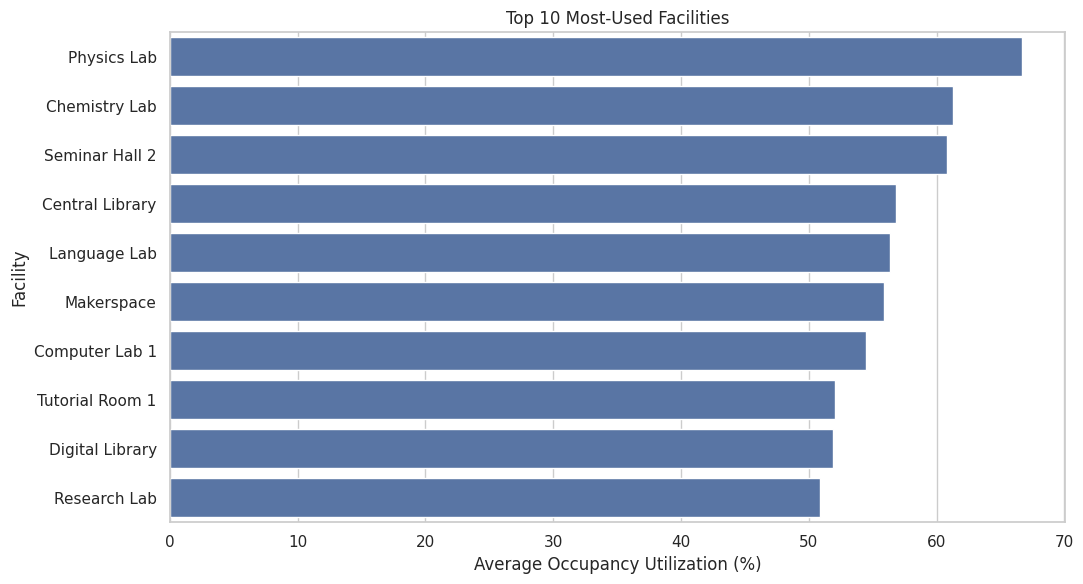

In [ ]:
# QUESTION 1: MOST-USED FACILITIES

display(Markdown("## 1. Most-Used Facilities"))

facility_col = "facility" if "facility" in occupancy.columns else "facility_name"

util_col = "occupancy_percentage"
if util_col not in occupancy.columns:
    raise ValueError("occupancy_percentage column not found in cleaned_occupancy.csv")

most_used = (
    occupancy.groupby(facility_col)
    .agg(
        Average_Utilization=(util_col, "mean"),
        Total_Readings=(util_col, "count")
    )
    .sort_values("Average_Utilization", ascending=False)
    .head(10)
    .reset_index()
)

most_used["Average_Utilization"] = most_used["Average_Utilization"].round(2)

display(most_used)
most_used.to_csv(os.path.join(output_path, "Q1_Most_Used_Facilities.csv"), index=False)

plt.figure(figsize=(11, 6))
sns.barplot(data=most_used, x="Average_Utilization", y=facility_col)
plt.title("Top 10 Most-Used Facilities")
plt.xlabel("Average Occupancy Utilization (%)")
plt.ylabel("Facility")
plt.tight_layout()
plt.savefig(os.path.join(graph_path, "Q1_Most_Used_Facilities.png"), dpi=300)
plt.show()

## 2. Peak Utilization Periods

,hour,Average_Utilization,Average_Occupants,Total_Readings
0,8,40.19,31.05,41
1,9,52.23,53.14,44
2,10,47.96,35.06,49
3,11,49.54,44.64,45
4,12,44.94,44.16,37
5,13,48.72,32.47,33
6,14,48.86,43.06,35
7,15,56.36,54.01,44
8,16,46.62,38.88,32
9,17,39.82,31.95,56


Peak hour: 15:00
Average utilization: 56.36%


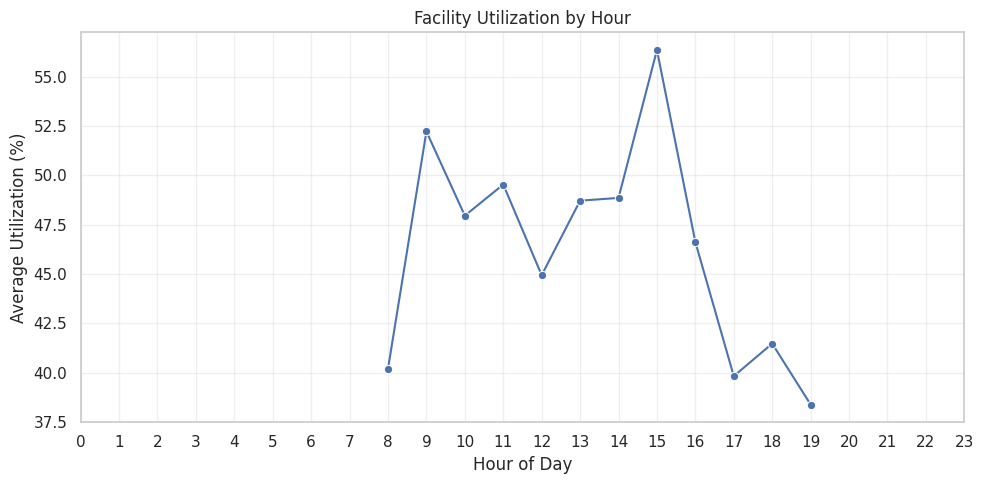

In [ ]:
# QUESTION 2: PEAK UTILIZATION PERIODS

display(Markdown("## 2. Peak Utilization Periods"))

occupancy["timestamp"] = pd.to_datetime(occupancy["timestamp"], errors="coerce")
occupancy["hour"] = occupancy["timestamp"].dt.hour

hourly_usage = (
    occupancy.groupby("hour")
    .agg(
        Average_Utilization=("occupancy_percentage", "mean"),
        Average_Occupants=("count_clean", "mean"),
        Total_Readings=("occupancy_percentage", "count")
    )
    .reset_index()
    .sort_values("hour")
)

hourly_usage[["Average_Utilization", "Average_Occupants"]] = (
    hourly_usage[["Average_Utilization", "Average_Occupants"]].round(2)
)

display(hourly_usage)
hourly_usage.to_csv(os.path.join(output_path, "Q2_Peak_Utilization_Periods.csv"), index=False)

peak_hour = hourly_usage.loc[hourly_usage["Average_Utilization"].idxmax()]
print(f"Peak hour: {int(peak_hour['hour']):02d}:00")
print(f"Average utilization: {peak_hour['Average_Utilization']:.2f}%")

plt.figure(figsize=(10, 5))
sns.lineplot(data=hourly_usage, x="hour", y="Average_Utilization", marker="o")
plt.xticks(range(0, 24))
plt.title("Facility Utilization by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Utilization (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(graph_path, "Q2_Peak_Utilization_Periods.png"), dpi=300)
plt.show()

## 3. Underused Facilities

,facility,Average_Utilization,Total_Readings
12,Innovation Hub,24.29,22


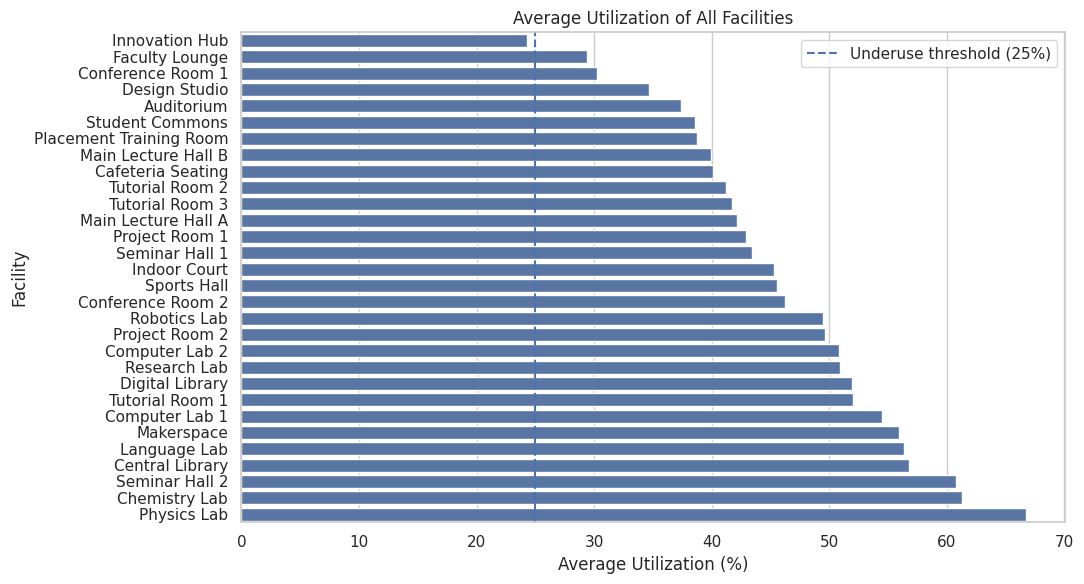

In [ ]:
# QUESTION 3: UNDERUSED FACILITIES

display(Markdown("## 3. Underused Facilities"))

underuse_threshold = 25

facility_usage = (
    occupancy.groupby(facility_col)
    .agg(
        Average_Utilization=("occupancy_percentage", "mean"),
        Total_Readings=("occupancy_percentage", "count")
    )
    .reset_index()
)

underused = (
    facility_usage[facility_usage["Average_Utilization"] < underuse_threshold]
    .sort_values("Average_Utilization")
    .copy()
)

underused["Average_Utilization"] = underused["Average_Utilization"].round(2)

if underused.empty:
    print(f"No facilities are below {underuse_threshold}% utilization.")
else:
    display(underused)

facility_usage.to_csv(os.path.join(output_path, "Q3_All_Facility_Usage.csv"), index=False)
underused.to_csv(os.path.join(output_path, "Q3_Underused_Facilities.csv"), index=False)

plt.figure(figsize=(11, 6))
plot_data = facility_usage.sort_values("Average_Utilization")
sns.barplot(data=plot_data, x="Average_Utilization", y=facility_col)
plt.axvline(underuse_threshold, linestyle="--", label="Underuse threshold (25%)")
plt.title("Average Utilization of All Facilities")
plt.xlabel("Average Utilization (%)")
plt.ylabel("Facility")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(graph_path, "Q3_Underused_Facilities.png"), dpi=300)
plt.show()

## 3B. Booking Frequency by Facility

,facility,Total_Bookings
7,Conference Room 2,27
26,Student Commons,25
28,Tutorial Room 2,25
2,Central Library,23
4,Computer Lab 1,22
20,Project Room 2,22
9,Digital Library,21
21,Research Lab,19
23,Seminar Hall 1,18
27,Tutorial Room 1,18


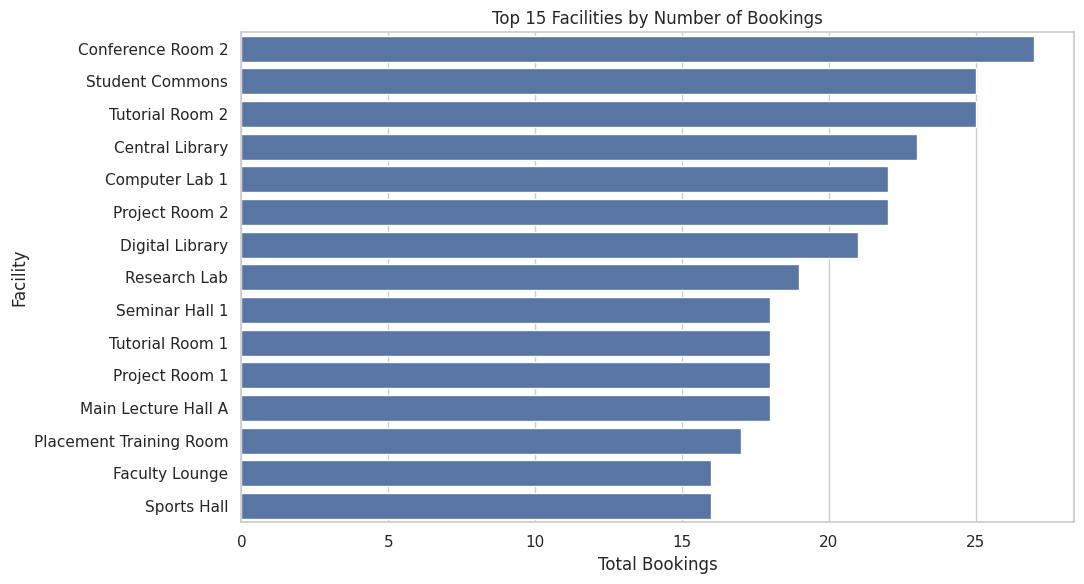

In [ ]:
# QUESTION 3B: BOOKING FREQUENCY

display(Markdown("## 3B. Booking Frequency by Facility"))

booking_facility_col = "facility" if "facility" in bookings.columns else "facility_name"

booking_frequency = (
    bookings.groupby(booking_facility_col)
    .size()
    .reset_index(name="Total_Bookings")
    .sort_values("Total_Bookings", ascending=False)
)

display(booking_frequency.head(15))
booking_frequency.to_csv(os.path.join(output_path, "Q3B_Booking_Frequency.csv"), index=False)

plt.figure(figsize=(11, 6))
sns.barplot(
    data=booking_frequency.head(15),
    x="Total_Bookings",
    y=booking_facility_col
)
plt.title("Top 15 Facilities by Number of Bookings")
plt.xlabel("Total Bookings")
plt.ylabel("Facility")
plt.tight_layout()
plt.savefig(os.path.join(graph_path, "Q3B_Booking_Frequency.png"), dpi=300)
plt.show()

## 4. Exam Period Impact

Occupancy readings: 500
Calendar-matched readings: 500
Unmatched readings: 0


,Period,Average_Occupancy,Average_Utilization,Number_of_Readings
0,Exam Period,32.29,51.99,17
1,Non-Exam Period,40.27,45.87,483


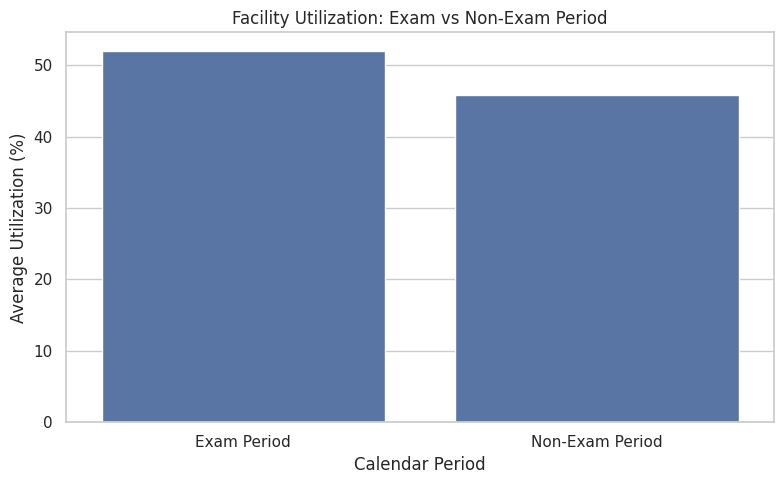


Interpretation:
Compare the average utilization and number of readings in both groups.


In [ ]:
# QUESTION 4: EXAM PERIOD VS NON-EXAM PERIOD

display(Markdown("## 4. Exam Period Impact"))

# Match occupancy readings to the calendar by date
occupancy["date"] = pd.to_datetime(occupancy["timestamp"], errors="coerce").dt.normalize()
calendar["date"] = pd.to_datetime(calendar["date"], errors="coerce").dt.normalize()

calendar_columns = ["date", "exam_period"]
if "working_day" in calendar.columns:
    calendar_columns.append("working_day")

calendar_subset = calendar[calendar_columns].drop_duplicates("date")

exam_data = occupancy.drop(
    columns=["exam_period", "working_day"],
    errors="ignore"
).merge(calendar_subset, on="date", how="left", indicator=True)

print("Occupancy readings:", len(exam_data))
print("Calendar-matched readings:", (exam_data["_merge"] == "both").sum())
print("Unmatched readings:", (exam_data["_merge"] == "left_only").sum())

# Convert exam labels to consistent yes/no values
def normalize_yes_no(series):
    return series.astype(str).str.strip().str.lower().map({
        "yes": "Exam Period",
        "true": "Exam Period",
        "1": "Exam Period",
        "no": "Non-Exam Period",
        "false": "Non-Exam Period",
        "0": "Non-Exam Period"
    })

exam_data["Period"] = normalize_yes_no(exam_data["exam_period"])
exam_data = exam_data.dropna(subset=["Period"])

exam_comparison = (
    exam_data.groupby("Period")
    .agg(
        Average_Occupancy=("count_clean", "mean"),
        Average_Utilization=("occupancy_percentage", "mean"),
        Number_of_Readings=("occupancy_percentage", "count")
    )
    .reset_index()
)

exam_comparison[["Average_Occupancy", "Average_Utilization"]] = (
    exam_comparison[["Average_Occupancy", "Average_Utilization"]].round(2)
)

display(exam_comparison)
exam_comparison.to_csv(os.path.join(output_path, "Q4_Exam_Period_Comparison.csv"), index=False)

if not exam_comparison.empty:
    plt.figure(figsize=(8, 5))
    sns.barplot(data=exam_comparison, x="Period", y="Average_Utilization")
    plt.title("Facility Utilization: Exam vs Non-Exam Period")
    plt.xlabel("Calendar Period")
    plt.ylabel("Average Utilization (%)")
    plt.tight_layout()
    plt.savefig(os.path.join(graph_path, "Q4_Exam_Period_Comparison.png"), dpi=300)
    plt.show()

    print("\nInterpretation:")
    print("Compare the average utilization and number of readings in both groups.")
    if len(exam_comparison) < 2:
        print("Only one period is represented. Check calendar date coverage before drawing conclusions.")
    elif exam_comparison["Number_of_Readings"].min() < 10:
        print("Warning: one period has fewer than 10 readings, so the comparison may be unreliable.")

## 5. Maintenance Downtime by Facility

,facility,Total_Downtime,Average_Downtime,Maintenance_Records
13,Language Lab,117.7,4.36,27
1,Cafeteria Seating,117.4,4.35,27
4,Computer Lab 1,109.5,6.08,18
21,Research Lab,107.1,5.95,18
11,Indoor Court,97.6,5.42,18
26,Student Commons,95.5,4.34,22
2,Central Library,93.6,5.51,17
10,Faculty Lounge,91.2,4.56,20
0,Auditorium,84.5,4.45,19
20,Project Room 2,83.4,5.96,14


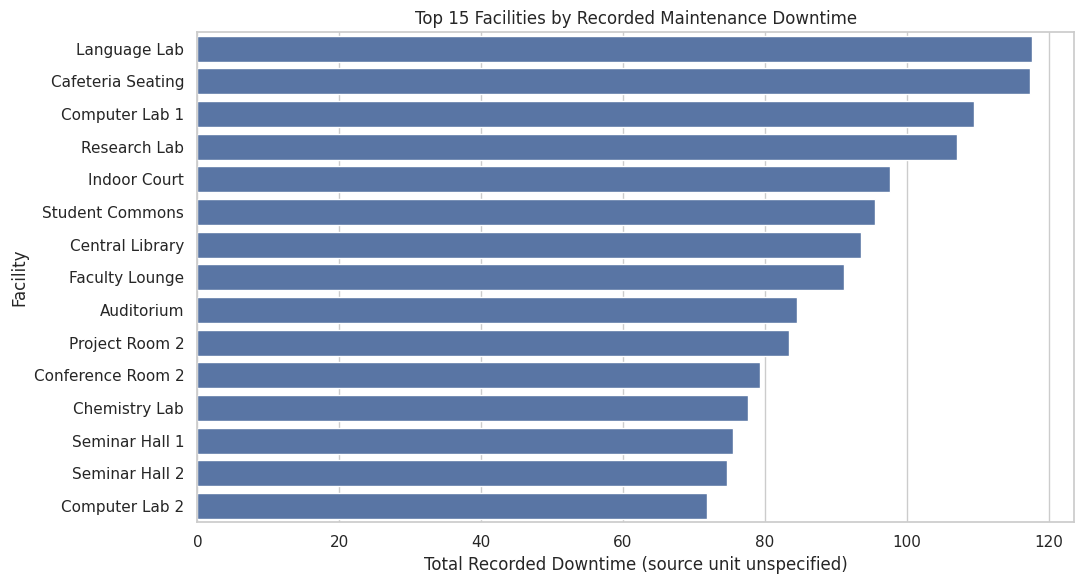

In [ ]:
# QUESTION 5: MAINTENANCE DOWNTIME BY FACILITY

display(Markdown("## 5. Maintenance Downtime by Facility"))

maintenance_facility_col = (
    "facility" if "facility" in maintenance.columns else "facility_name"
)

downtime_col = (
    "downtime_clean" if "downtime_clean" in maintenance.columns
    else "downtime"
)

maintenance[downtime_col] = pd.to_numeric(
    maintenance[downtime_col], errors="coerce"
)

downtime_summary = (
    maintenance.groupby(maintenance_facility_col)
    .agg(
        Total_Downtime=(downtime_col, "sum"),
        Average_Downtime=(downtime_col, "mean"),
        Maintenance_Records=(downtime_col, "count")
    )
    .reset_index()
    .sort_values("Total_Downtime", ascending=False)
)

downtime_summary[["Total_Downtime", "Average_Downtime"]] = (
    downtime_summary[["Total_Downtime", "Average_Downtime"]].round(2)
)

display(downtime_summary.head(15))
downtime_summary.to_csv(os.path.join(output_path, "Q5_Downtime_By_Facility.csv"), index=False)

plt.figure(figsize=(11, 6))
sns.barplot(
    data=downtime_summary.head(15),
    x="Total_Downtime",
    y=maintenance_facility_col
)
plt.title("Top 15 Facilities by Recorded Maintenance Downtime")
plt.xlabel("Total Recorded Downtime (source unit unspecified)")
plt.ylabel("Facility")
plt.tight_layout()
plt.savefig(os.path.join(graph_path, "Q5_Downtime_By_Facility.png"), dpi=300)
plt.show()

## 5B. Frequent Maintenance Issues

,issue,Work_Orders,Total_Downtime,Average_Downtime
7,Lighting fault,43,199.8,4.65
0,Air conditioning repair,41,145.3,3.54
13,Sensor calibration,40,197.8,4.94
4,Furniture damage,38,149.6,3.94
9,Plumbing leak,35,195.4,5.58
8,Network outage,35,172.2,4.92
1,Cleaning delay,35,127.8,3.65
12,Safety inspection,35,157.4,4.50
10,Power interruption,34,166.3,4.89
5,HVAC issue,34,167.6,4.93


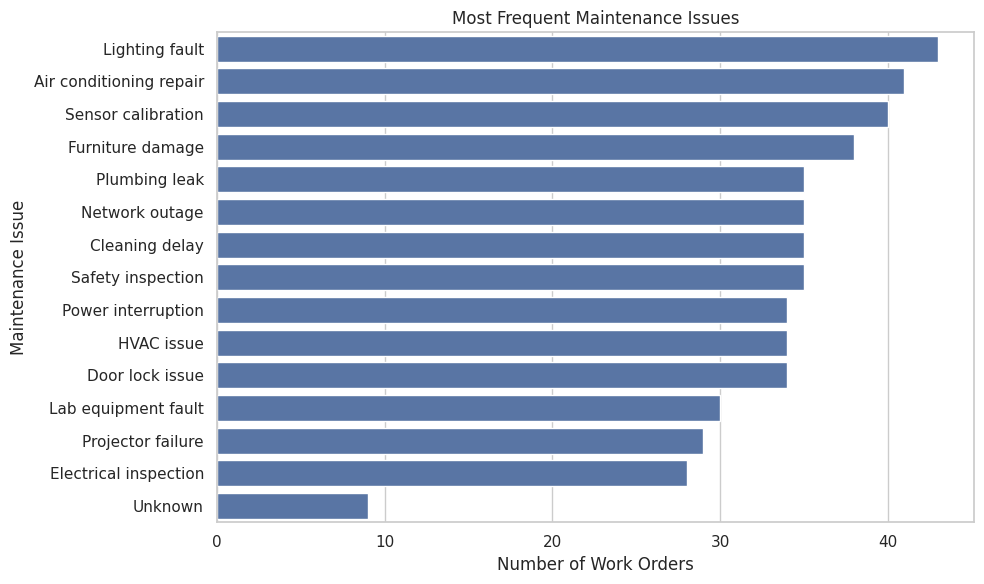

In [ ]:
# QUESTION 5B: FREQUENT MAINTENANCE ISSUES

display(Markdown("## 5B. Frequent Maintenance Issues"))

issue_col = "issue" if "issue" in maintenance.columns else "issue_type"

maintenance[issue_col] = (
    maintenance[issue_col].fillna("Unknown").astype(str).str.strip()
)
maintenance.loc[maintenance[issue_col] == "", issue_col] = "Unknown"

issue_summary = (
    maintenance.groupby(issue_col)
    .agg(
        Work_Orders=(issue_col, "size"),
        Total_Downtime=(downtime_col, "sum"),
        Average_Downtime=(downtime_col, "mean")
    )
    .reset_index()
    .sort_values("Work_Orders", ascending=False)
)

issue_summary[["Total_Downtime", "Average_Downtime"]] = (
    issue_summary[["Total_Downtime", "Average_Downtime"]].round(2)
)

display(issue_summary)
issue_summary.to_csv(os.path.join(output_path, "Q5B_Maintenance_By_Issue.csv"), index=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=issue_summary.head(15), x="Work_Orders", y=issue_col)
plt.title("Most Frequent Maintenance Issues")
plt.xlabel("Number of Work Orders")
plt.ylabel("Maintenance Issue")
plt.tight_layout()
plt.savefig(os.path.join(graph_path, "Q5B_Maintenance_By_Issue.png"), dpi=300)
plt.show()